[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/josterri/predicting-the-next-words-notebooks/blob/main/ch11-simple_workbook.ipynb)

# Loss and the length of the text

A bigram model trained on chapter 1 of Pride and Prejudice predicts chapters
52 to 61 badly. Trained on all 51 chapters before them, it reads far more
words and predicts them better. Does its loss fall on a straight line on
log-log axes, as Kaplan's loss falls with the parameters of a Transformer?

In [1]:
#@title Setup: run this cell first
import math
import os
import re
import urllib.request
from collections import Counter

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

MIRROR_REF = "main"
TEXT_URL = f"https://raw.githubusercontent.com/josterri/predicting-the-next-words-notebooks/{MIRROR_REF}/data/pride_and_prejudice.txt"


def load_novel():
    """Pride and Prejudice as lowercase word tokens, one list per chapter."""
    if os.environ.get("PNW_TEXT"):
        text = open(os.environ["PNW_TEXT"], encoding="utf-8").read()
    else:
        try:
            text = urllib.request.urlopen(TEXT_URL).read().decode("utf-8")
        except OSError as e:
            raise RuntimeError(f"The text did not download from {TEXT_URL}: {e}. "
                               "Run this cell again; every cell below needs it.") from None
    chapters = re.split(r"(?m)^CHAPTER [IVXLC]+\.$", text)[1:]
    return [re.findall(r"[a-z]+(?:'[a-z]+)*", c.lower().replace("’", "'")) for c in chapters]


# Chapters 1 to 51 train and chapters 52 to 61 are held out: every loss and every guess is measured on the held-out ones.
FIRST_HELD, LAST = 52, 61
SIZES = (1, 2, 4, 8, 16, 32, 51)  # the training runs: the first chapters, doubling, then all 51
MIX = 1 / 2  # the bigram's rate and the word's overall rate, half each, so no word gets probability zero
plt.rcParams.update({"xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8})


class Refused(Exception):  # a setting a cell refuses: Colab prints the one sentence, without the stack
    _render_traceback_ = lambda self: [str(self)]  # noqa: E731


def whole(name, x, lo, hi):  # a whole number typed in a cell
    if type(x) is not int or not lo <= x <= hi:
        raise Refused(f"{name} is {x!r}: {name} takes a whole number from {lo:,} to {hi:,}.")
    return x


def yours(name, lo, hi, answered, say):  # a sentence on the student's setting, when it is valid and not yet answered
    x = globals().get(name)
    return say(x) if type(x) is int and lo <= x <= hi and x not in answered else ""


def fit(xs, ys):  # the least-squares line through (log10 x, log10 y): slope and intercept
    lx, ly = [math.log10(x) for x in xs], [math.log10(y) for y in ys]
    mx, my = sum(lx) / len(lx), sum(ly) / len(ly)
    slope = sum((a - mx) * (b - my) for a, b in zip(lx, ly)) / sum((a - mx) ** 2 for a in lx)
    return slope, my - slope * mx


def loglog(title, xlabel, ylabel):  # a chart on log-log axes
    fig, ax = plt.subplots(figsize=(6, 3.4), layout="constrained")
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel, xscale="log", yscale="log")
    if ylabel.startswith("loss"):  # a span inside one decade: its ticks 6 and 7 printed plainly
        ax.yaxis.set_minor_formatter(plt.FormatStrFormatter("%g"))
    return ax


chapters = load_novel()
train, held = chapters[:FIRST_HELD - 1], chapters[FIRST_HELD - 1:LAST]
counts = [n for _, n in Counter(w for c in chapters for w in c).most_common()]  # counts by rank, rank 1 first
vocab = {w for c in train for w in c}
held_pairs = [(a, b) for c in held for a, b in zip(c, c[1:])]
words_in = {n: sum(map(len, train[:n])) for n in range(1, len(train) + 1)}  # training words of the first n chapters


def zipf(first, last):  # step 1: word counts by rank, and the line fitted from rank first to rank last
    first, last = whole("FIRST", first, 1, len(counts) - 1), whole("LAST_RANK", last, first + 1, len(counts))
    slope, icpt = fit(range(first, last + 1), counts[first - 1:last])
    print(f"{len(counts):,} word types; the line through ranks {first:,} to {last:,} has slope {slope:.2f}")
    ax = loglog("Pride and Prejudice, every word type", "rank of the word", "count")
    ax.plot(range(1, len(counts) + 1), counts, ".", ms=2, color="0.6")
    ax.plot([first, last], [10 ** (icpt + slope * math.log10(r)) for r in (first, last)], color="C3")
    plt.show()
    return slope


# Step 2: a bigram model of the first n chapters, and its loss on the held-out chapters in nats per word.
def bigram(n):
    uni, pair, ctx = Counter(), Counter(), Counter()
    for c in train[:n]:
        uni.update(c)
        pair.update(zip(c, c[1:]))
        ctx.update(c[:-1])
    return uni, pair, ctx


def loss(n):  # every word chapters 1 to 51 never use shares one slot of the word rates
    uni, pair, ctx = bigram(n)
    total, slots = sum(uni.values()), len(vocab) + 1
    rate = lambda b: (uni[b] + 1) / (total + slots)  # noqa: E731
    return sum(-math.log(MIX * pair[a, b] / ctx[a] + (1 - MIX) * rate(b) if ctx[a] else rate(b))
               for a, b in held_pairs) / len(held_pairs)


LOSS = {n: loss(n) for n in SIZES}


def losses(n):
    ns = sorted(set(SIZES) | {whole("CHAPTERS", n, 1, len(train))})
    LOSS[n] = LOSS.get(n) or loss(n)
    print("; ".join(f"{m} chapter{'s' * (m != 1)}, {words_in[m]:,} words: {LOSS[m]:.3f}" for m in ns))
    ax = loglog(f"a bigram model, loss on chapters {FIRST_HELD} to {LAST}", "training words", "loss, nats per word")
    ax.plot([words_in[m] for m in ns], [LOSS[m] for m in ns], "o-", color="C0")
    ax.plot([words_in[n]], [LOSS[n]], "o", color="C3", ms=9)
    plt.show()


# Step 3: the bigram's top guess for each held-out word, the most frequent word after the word before it; a tie goes to the
# word more frequent overall, then to the one seen first; after a word never seen, the training chapters' most frequent word.
def guesses(n):
    uni, pair, _ = bigram(n)
    best = {}
    for (a, b), k in pair.items():
        if a not in best or (k, uni[b]) > (pair[a, best[a]], uni[best[a]]):
            best[a] = b
    top = uni.most_common(1)[0][0]
    return [[best.get(a, top) == b for a, b in zip(c, c[1:])] for c in held]


HITS = {n: guesses(n) for n in SIZES}


def exact(n, k):  # the share of k-word windows inside a chapter with every guess right; k = 1 gives per-word accuracy
    wins = [all(hs[i:i + k]) for hs in HITS[n] for i in range(len(hs) - k + 1)]
    return sum(wins) / len(wins)


def scores(k):
    rows = [(exact(n, 1), exact(n, whole("K", k, 1, 5))) for n in SIZES]
    print("; ".join(f"{n} chapter{'s' * (n != 1)}: {100 * p:.2f}, {100 * e:.3f}, {100 * p ** k:.3f}" for n, (p, e) in zip(SIZES, rows))
          + " (per cent: per word, exact match, per word to the power K)")
    fig, ax = plt.subplots(figsize=(6, 3.4), layout="constrained")
    for y, label, color in ((0, "per-word accuracy", "C0"), (1, f"exact match, {k}-word windows", "C3")):
        ax.plot(SIZES, [100 * r[y] for r in rows], "o-", color=color, label=label)
    ax.plot(SIZES, [100 * r[0] ** k for r in rows], "o--", color="0.5", label=f"per-word accuracy to the power {k}")
    ax.set(title=f"guesses on chapters {FIRST_HELD} to {LAST}", xlabel="training chapters", ylabel="per cent", xscale="log")
    ax.set_xticks(SIZES, [str(n) for n in SIZES])
    ax.legend()
    plt.show()


# Appendix: the line through the runs of up to `upto` chapters, extended to the larger runs.
def extrapolate(upto):
    if type(upto) is not int or upto not in SIZES[1:-1]:
        raise Refused(f"FIT_UP_TO is {upto!r}: FIT_UP_TO takes one of {', '.join(map(str, SIZES[1:-1]))}.")
    slope, icpt = fit(*zip(*[(words_in[n], LOSS[n]) for n in SIZES if n <= upto]))
    line = {n: 10 ** (icpt + slope * math.log10(words_in[n])) for n in SIZES}
    print(f"slope {slope:.4f}; " + "; ".join(f"{n} chapters: line {line[n]:.3f}, measured {LOSS[n]:.3f}" for n in SIZES if n > upto))
    ax = loglog(f"a line fitted on 1 to {upto} chapters", "training words", "loss, nats per word")
    ax.plot([words_in[n] for n in SIZES], [LOSS[n] for n in SIZES], "o", color="C0", label="measured")
    ax.plot([words_in[n] for n in SIZES], [line[n] for n in SIZES], color="C3", label="fitted line")
    ax.legend()
    plt.show()
    return line


display(Markdown(f"The novel: {len(chapters)} chapters, {len(counts):,} word types. Chapters 1 to {FIRST_HELD - 1} train: {words_in[len(train)]:,} words. "
                 f"Chapters {FIRST_HELD} to {LAST} are held out: every loss and every guess is measured on their {len(held_pairs):,} words that follow a word."))

The novel: 61 chapters, 6,314 word types. Chapters 1 to 51 train: 100,116 words. Chapters 52 to 61 are held out: every loss and every guess is measured on their 22,048 words that follow a word.

## 1. Word counts on log-log axes

A power law is a straight line on log-log axes. The cell ranks the novel's
words from the most frequent down and fits a line to the logarithm of each
count against the logarithm of its rank, from rank `FIRST` to rank
`LAST_RANK`. Run the cell for ranks 10 to 631, about one tenth of the word
types. Then set `FIRST` to 1 and `LAST_RANK` to the number of word types the
setup printed: what slope does the line take over every rank?

6,314 word types; the line through ranks 10 to 631 has slope -1.10


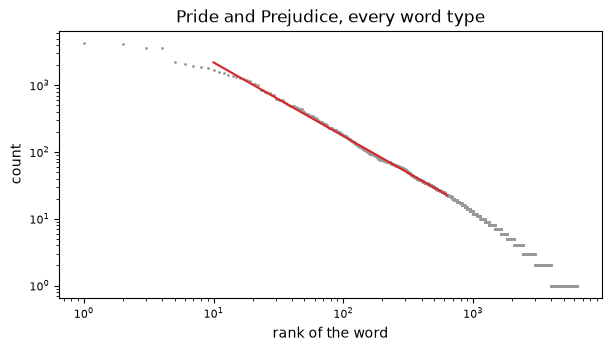

-1.1033354902056067

In [2]:
FIRST, LAST_RANK = 10, 631
zipf(FIRST, LAST_RANK)

### Solution

6,314 word types; the line through ranks 10 to 631 has slope -1.10
6,314 word types; the line through ranks 1 to 6,314 has slope -1.35


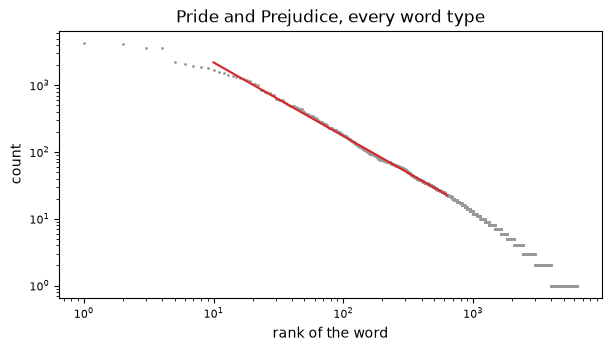

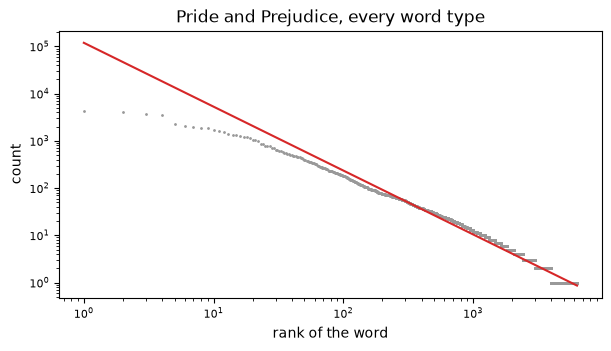

Between ranks 10 and 631 the counts fall on a line of slope -1.10; over every rank, 1 to 6,314, the line takes -1.35. Most of its points lie past rank 631, where the counts fall at -1.53 and 3,296 words occur once or twice. The course corpus gives -0.899 between ranks 10 and 627: both are power laws of the rank.

In [3]:
s10, s1, tail = zipf(10, 631), zipf(1, len(counts)), fit(range(632, len(counts) + 1), counts[631:])[0]
display(Markdown(f"Between ranks 10 and 631 the counts fall on a line of slope {s10:.2f}; over every rank, 1 to {len(counts):,}, the line takes "
                 f"{s1:.2f}. Most of its points lie past rank 631, where the counts fall at {tail:.2f} and {sum(n <= 2 for n in counts):,} words "
                 f"occur once or twice. The course corpus gives -0.899 between ranks 10 and 627: both are power laws of the rank."))

## 2. Loss against training words

The cell trains a bigram model on the first `CHAPTERS` chapters and measures
its loss on chapters 52 to 61: the mean of minus the natural logarithm of
the probability it gives each word after the word before, in nats. Its
probability mixes the bigram's rate with the word's overall rate, half each.
Run the cell with 16 chapters. Then set `CHAPTERS` to 51: how much lower is
the loss, and do the seven runs fall on one line?

1 chapter, 853 words: 7.439; 2 chapters, 1,652 words: 7.015; 4 chapters, 4,420 words: 6.475; 8 chapters, 11,671 words: 6.104; 16 chapters, 25,831 words: 5.866; 32 chapters, 56,415 words: 5.658; 51 chapters, 100,116 words: 5.518


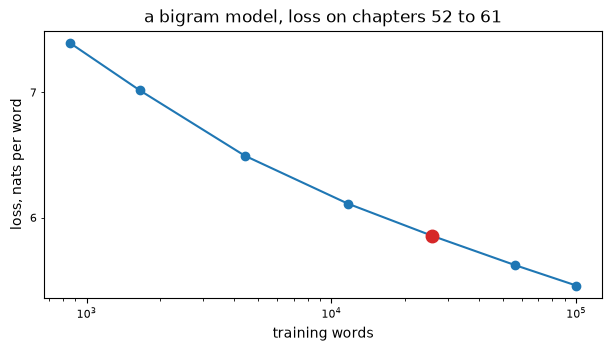

In [4]:
CHAPTERS = 16
losses(CHAPTERS)

### Solution

In [5]:
steps = [math.log(LOSS[a] / LOSS[b]) / math.log(words_in[b] / words_in[a]) for a, b in zip(SIZES, SIZES[1:])]
display(Markdown(f"Trained on 16 chapters the model loses {LOSS[16]:.3f} nats per word on chapters {FIRST_HELD} to {LAST}, on 51 chapters "
                 f"{LOSS[51]:.3f}, and on chapter 1 alone {LOSS[1]:.3f}. Between neighbouring runs the local exponent goes from "
                 f"{steps[0]:.3f} to {steps[-1]:.3f}, so the points bend: each doubling of the words buys a smaller share of the loss."
                 + yours("CHAPTERS", 1, len(train), (16, 51), lambda n: f" With `CHAPTERS` at {n}: {LOSS[n]:.3f} nats on {words_in[n]:,} words.")))

Trained on 16 chapters the model loses 5.866 nats per word on chapters 52 to 61, on 51 chapters 5.518, and on chapter 1 alone 7.439. Between neighbouring runs the local exponent goes from 0.089 to 0.044, so the points bend: each doubling of the words buys a smaller share of the loss.

## 3. Per-word accuracy and exact match

Exact match counts an answer right only when every part is right. The cell
takes the bigram's top guess for each word of chapters 52 to 61 and scores
windows of `K` consecutive words by exact match. If the guesses were right
independently, at a per-word accuracy p, exact match would be p to the power
`K`, the grey line. Run the cell with `K` at 2. Then set `K` to 3: how does
exact match move as the training chapters grow?

1 chapter: 4.39, 0.177, 0.193; 2 chapters: 5.14, 0.318, 0.265; 4 chapters: 7.21, 0.404, 0.520; 8 chapters: 8.83, 0.658, 0.779; 16 chapters: 10.55, 0.876, 1.112; 32 chapters: 11.62, 0.853, 1.349; 51 chapters: 12.31, 0.780, 1.515 (per cent: per word, exact match, per word to the power K)


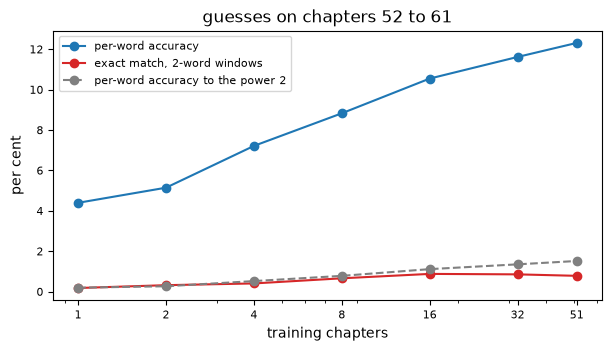

In [6]:
K = 2
scores(K)

### Solution

In [7]:
(p1, e1), (p51, e51), e3 = (exact(1, 1), exact(1, 2)), (exact(51, 1), exact(51, 2)), [exact(n, 3) for n in SIZES]
after = [hs[i + 1] for hs in HITS[51] for i in range(len(hs) - 1) if hs[i]]
display(Markdown(f"Per-word accuracy rises from {100 * p1:.2f} per cent on 1 chapter to {100 * p51:.2f} on 51, while exact match on two-word "
                 f"windows goes from {100 * e1:.3f} to {100 * e51:.3f} per cent, against {100 * p51 ** 2:.3f} for p squared; on three-word windows "
                 f"it stays between {100 * min(e3):.3f} and {100 * max(e3):.3f}. With 51 chapters the guess after a right guess is right "
                 f"{100 * sum(after) / len(after):.2f} per cent of the time, so the guesses are not independent."
                 + yours("K", 1, 5, (2, 3), lambda k: f" With `K` at {k}, 51 chapters give {100 * exact(51, k):.3f} per cent.")))

Per-word accuracy rises from 4.39 per cent on 1 chapter to 12.31 on 51, while exact match on two-word windows goes from 0.177 to 0.780 per cent, against 1.515 for p squared; on three-word windows it stays between 0.000 and 0.086. With 51 chapters the guess after a right guess is right 6.34 per cent of the time, so the guesses are not independent.

## Appendix. Predicting a larger run

Kaplan's lines are fitted on small runs and extended to large ones. The cell
fits a line to the loss against the training words, on log-log axes, for the
runs of 1 to 16 chapters, and extends it to the runs of 32 and 51 chapters.

slope -0.0699; 32 chapters: line 5.495, measured 5.658; 51 chapters: line 5.279, measured 5.518


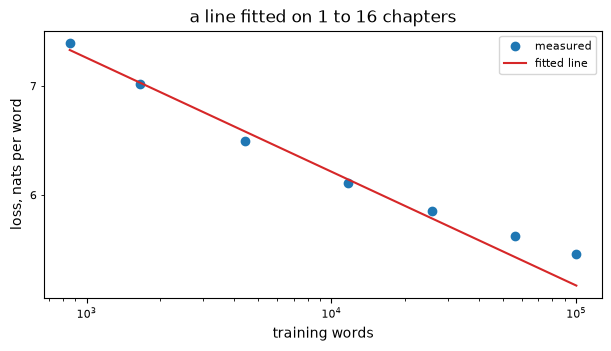

In [8]:
line16 = extrapolate(16)

**Exercise.** Set `FIT_UP_TO` to 32, fitting the first six runs. How far is
the line's prediction for 51 chapters from the measured loss?

slope -0.0651; 51 chapters: line 5.372, measured 5.518


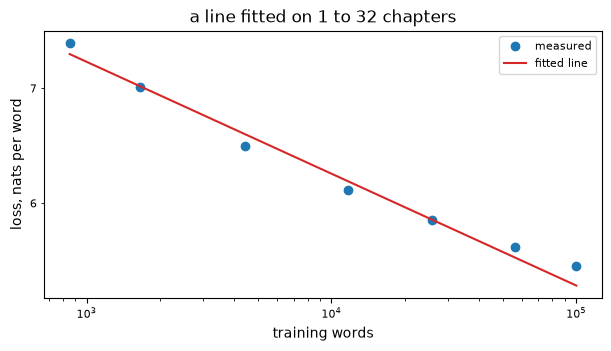

In [9]:
FIT_UP_TO = 32

line = extrapolate(FIT_UP_TO)

### Solution

slope -0.0651; 51 chapters: line 5.372, measured 5.518


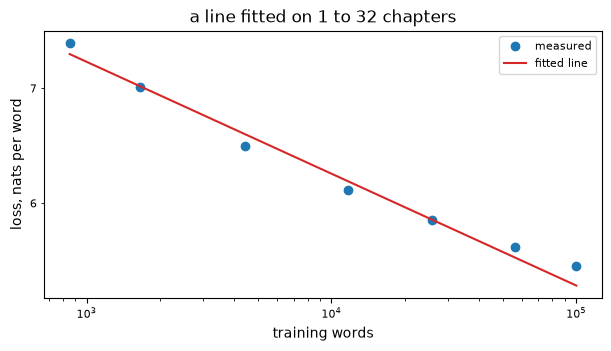

Fitted on 1 to 16 chapters, the line predicts 5.279 nats for 51 chapters and the run measures 5.518, 0.239 above it; fitted on 1 to 32 chapters, it predicts 5.372, and the run is 0.146 above that line. The measured points bend away from a straight line, so a line fitted on small runs promises the large run a lower loss than it reaches.

In [10]:
line32 = extrapolate(32)
display(Markdown(f"Fitted on 1 to 16 chapters, the line predicts {line16[51]:.3f} nats for 51 chapters and the run measures {LOSS[51]:.3f}, "
                 f"{LOSS[51] - line16[51]:.3f} above it; fitted on 1 to 32 chapters, it predicts {line32[51]:.3f}, and the run is "
                 f"{LOSS[51] - line32[51]:.3f} above that line. The measured points bend away from a straight line, so a line fitted on "
                 f"small runs promises the large run a lower loss than it reaches."))